# Compare the models

All statistics, tables and figures for every model run with `run_model.ipynb` (same questions, conditions, prompts, frames and option orders) and coded with `code_explanations.ipynb`. Every model in `configs/models.toml` whose results and codes are in `outputs/<model>/` is included; to add a model, run it and its coding, then rerun this notebook. No model needed. Outputs: `outputs/compare_models/`.

In [1]:
import tomllib
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, chi2_contingency, chisquare, mannwhitneyu, wilcoxon

ROOT = Path.cwd().parent
EXP_DIR = ROOT / "outputs/compare_models"
FIGURES = EXP_DIR / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
MODELS = {name: m["label"] for name, m in tomllib.loads((ROOT / "configs/models.toml").read_text()).items()
          if (ROOT / "outputs" / name / "judge_labels.jsonl").exists()}
CONDITIONS = ["Q_noE", "Q", "T", "T_told", "VT", "VTmis"]
WITH_E = CONDITIONS[1:]
CODES = ["cites_dialogue", "cites_visual", "says_insufficient", "names_missing_visual", "notices_mismatch"]
HIGH_CONFIDENCE = 0.8
ABCD = ["prob_A", "prob_B", "prob_C", "prob_D"]

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]
info = pd.read_parquet(ROOT / "data-private/processed/emotion_questions.parquet").set_index("question_id")


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half


def load(name):
    df = pd.read_json(ROOT / "outputs" / name / "results.jsonl", lines=True).drop_duplicates(["question_id", "condition"])
    df = df.merge(keys, on="question_id")
    df["abstain"] = df.answer == "E"
    df["p_E"] = df.prob_E.fillna(0)
    df["correct"] = df.answer == df.correct_answer_key
    df["confidence"] = df[ABCD].max(axis=1) / df[ABCD].sum(axis=1)
    df["confidently_wrong"] = ~df.correct & ~df.abstain & (df.confidence >= HIGH_CONFIDENCE)
    df["forced_correct"] = df[ABCD].idxmax(axis=1).str[-1] == df.correct_answer_key
    df["claims_video"] = df.evidence_answer.isin(["video", "both"])
    df["cue_visual_any"] = df.question_id.map(info.cue_visual_any)
    df["no_dialogue"] = df.question_id.map(info.focused_n_words) == 0
    labels = pd.read_json(ROOT / "outputs" / name / "judge_labels.jsonl", lines=True, dtype={"prompt_sha": str})
    both = labels.groupby("key")[CODES].all()
    df["key"] = df.question_id + "|" + df.condition
    return df.merge(both, left_on="key", right_index=True, how="left")


data = {label: load(name) for name, label in MODELS.items()}
for name, df in data.items():
    print(name, df.question_id.nunique(), "questions,", len(df), "rows,", df[CODES[0]].isna().sum(), "without codes")

Qwen-Omni 598 questions, 3588 rows, 0 without codes
InternVL 598 questions, 3588 rows, 0 without codes
Qwen-VL 598 questions, 3588 rows, 0 without codes
LLaVA-Video 598 questions, 3588 rows, 0 without codes
Gemma 598 questions, 3588 rows, 0 without codes
GLM 598 questions, 3588 rows, 0 without codes
PLM 598 questions, 3588 rows, 0 without codes


## Behavior

In [2]:
summary = pd.concat({name: df.groupby("condition").agg(
    abstain=("abstain", "mean"),
    mean_p_E=("p_E", "mean"),
    accuracy=("correct", "mean"),
    best_abcd_right=("forced_correct", "mean"),
    confidently_wrong=("confidently_wrong", "mean"),
    mass_on_letters=("mass_on_letters", "mean"),
).reindex(CONDITIONS) for name, df in data.items()}, axis=1)
summary.to_csv(EXP_DIR / "summary.csv")
(summary * 100).round(1)

Qwen-Omni                                                      \
            abstain mean_p_E accuracy best_abcd_right confidently_wrong   
condition                                                                 
Q_noE           0.0      0.0     43.6            44.1              16.6   
Q              61.7     54.1     19.4            45.3               9.0   
T              47.5     44.6     32.1            54.7              12.0   
T_told         61.9     56.5     25.3            55.2               8.0   
VT             29.4     30.1     42.0            56.2              13.9   
VTmis          41.6     39.4     32.6            52.5              15.1   

                          InternVL                                    ...  \
          mass_on_letters  abstain mean_p_E accuracy best_abcd_right  ...   
condition                                                             ...   
Q_noE               100.0      0.0      0.0     44.3            44.5  ...   
Q                   100.0     58.7     50.3     18.9            43.0  ...   
T                   100.0     42.0     41.0     32.4            51.2  ...   
T_told              100.0     53.8     49.5     29.1            52.7  ...   
VT                  100.0     13.7     16.9     49.0            56.4  ...   
VTmis               100.0     15.7     19.7     42.1            49.0  ...   

               GLM                                                       PLM  \
          accuracy best_abcd_right confidently_wrong mass_on_letters abstain   
condition                                                                      
Q_noE         44.1            43.8              40.8           100.0     0.0   
Q             16.9            40.8              15.4           100.0    15.9   
T             33.1            52.8              14.0           100.0    30.6   
T_told        32.3            54.8              12.4           100.0    31.9   
VT            45.5            64.7              12.9           100.0    17.2   
VTmis         23.1            52.3              10.7           100.0    32.9   

                                                                               
          mean_p_E accuracy best_abcd_right confidently_wrong mass_on_letters  
condition                                                                      
Q_noE          0.0     40.3            39.8              12.7            99.7  
Q             17.9     34.4            39.6              10.9            99.8  
T             28.9     40.0            52.3              11.7            99.9  
T_told        30.5     39.1            52.3              11.7            99.9  
VT            20.7     49.0            57.0              16.9            99.9  
VTmis         32.9     35.5            47.5              18.4            99.9  

[6 rows x 42 columns]

In [3]:
for name, df in data.items():
    print(f"===== {name}")
    abstained = df.pivot(index="question_id", columns="condition", values="abstain")
    for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
        start = int((~abstained[a] & abstained[b]).sum())
        stop = int((abstained[a] & ~abstained[b]).sum())
        print(f"abstain {a} -> {b}: {start} start, {stop} stop; exact McNemar p = {binomtest(start, start + stop).pvalue:.2g}")
    right = df.pivot(index="question_id", columns="condition", values="forced_correct")
    for a, b in [("Q", "T"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
        gain = int((~right[a] & right[b]).sum())
        loss = int((right[a] & ~right[b]).sum())
        print(f"best A-D right {a} -> {b}: {gain} gained, {loss} lost; exact McNemar p = {binomtest(gain, gain + loss).pvalue:.2g}")
    pE = df.pivot(index="question_id", columns="condition", values="p_E")
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    video_mattered = answers["VT"] != answers["T"]
    rise = pE["T_told"] - pE["T"]
    print(f"P(E) rise T -> T_told: video mattered {rise[video_mattered].mean():+.3f} (n = {video_mattered.sum()}), "
          f"did not {rise[~video_mattered].mean():+.3f} (n = {(~video_mattered).sum()}); "
          f"Mann-Whitney p = {mannwhitneyu(rise[video_mattered], rise[~video_mattered]).pvalue:.2g}")

===== Qwen-Omni
abstain Q -> T: 39 start, 124 stop; exact McNemar p = 1.6e-11
abstain T -> T_told: 87 start, 1 stop; exact McNemar p = 5.8e-25
abstain T -> VT: 19 start, 127 stop; exact McNemar p = 8.4e-21
abstain VT -> VTmis: 101 start, 28 stop; exact McNemar p = 7e-11
abstain T -> VTmis: 47 start, 82 stop; exact McNemar p = 0.0026
best A-D right Q -> T: 109 gained, 53 lost; exact McNemar p = 1.3e-05
best A-D right T -> VT: 54 gained, 45 lost; exact McNemar p = 0.42
best A-D right VT -> VTmis: 42 gained, 64 lost; exact McNemar p = 0.041
best A-D right T -> VTmis: 48 gained, 61 lost; exact McNemar p = 0.25
P(E) rise T -> T_told: video mattered +0.137 (n = 185), did not +0.111 (n = 413); Mann-Whitney p = 0.00018
===== InternVL
abstain Q -> T: 64 start, 164 stop; exact McNemar p = 2.7e-11
abstain T -> T_told: 72 start, 1 stop; exact McNemar p = 1.6e-20
abstain T -> VT: 14 start, 183 stop; exact McNemar p = 1e-38
abstain VT -> VTmis: 47 start, 35 stop; exact McNemar p = 0.22
abstain T -> 

In [4]:
abstained = pd.concat({name: df.pivot(index="question_id", columns="condition", values="abstain")
                       for name, df in data.items()}, axis=1)
all_abstain = pd.concat([abstained[name] for name in data]).groupby(level=0).all()
none_abstain = ~pd.concat([abstained[name] for name in data]).groupby(level=0).any()
pd.DataFrame({"all abstain": all_abstain.mean(), "same decision": (all_abstain | none_abstain).mean()}).reindex(WITH_E).round(3)

,all abstain,same decision
condition,,
Q,0.062,0.072
T,0.065,0.157
T_told,0.084,0.145
VT,0.020,0.381
VTmis,0.055,0.189


## Per model: confidence intervals, option position, letter mass, run time

In [5]:
SHOWN = ["A", "B", "C", "D", "E"]
for name, df in data.items():
    print(f"===== {name}")
    abstained = df.pivot(index="question_id", columns="condition", values="abstain")
    for c in WITH_E:
        lo, hi = wilson(abstained[c].sum(), len(abstained))
        print(f"{c:7} abstained {abstained[c].mean():.1%}  95% CI [{lo:.1%}, {hi:.1%}]")
    e_shown = df.option_order.str.find("E").map(dict(enumerate(SHOWN)))
    p = [chi2_contingency(pd.crosstab(e_shown[df.condition == c], df.abstain[df.condition == c]))[1] for c in WITH_E]
    print("abstention vs letter of 'Cannot tell', chi-square p by condition:", {c: f"{x:.2g}" for c, x in zip(WITH_E, p)})
    no_e = df[df.condition == "Q_noE"]
    letters = no_e.answer_shown.value_counts().reindex(["A", "B", "C", "D"], fill_value=0)
    print(f"Q_noE answers by shown letter {letters.to_dict()}; chi-square vs equal p = {chisquare(letters).pvalue:.2g}")
    print(f"Q_noE: less than half of the probability on the letters in {(no_e.mass_on_letters < 0.5).mean():.1%}")
    seconds = df.score_seconds + df.explain_seconds + df.evidence_seconds
    print(f"run time {seconds.sum() / 3600:.1f} GPU-hours ({seconds.groupby(df.question_id).sum().mean():.0f} s per question)")

===== Qwen-Omni
Q       abstained 61.7%  95% CI [57.7%, 65.5%]
T       abstained 47.5%  95% CI [43.5%, 51.5%]
T_told  abstained 61.9%  95% CI [57.9%, 65.7%]
VT      abstained 29.4%  95% CI [25.9%, 33.2%]
VTmis   abstained 41.6%  95% CI [37.8%, 45.6%]
abstention vs letter of 'Cannot tell', chi-square p by condition: {'Q': '0.18', 'T': '0.55', 'T_told': '0.75', 'VT': '0.63', 'VTmis': '0.98'}
Q_noE answers by shown letter {'A': 173, 'B': 162, 'C': 146, 'D': 117}; chi-square vs equal p = 0.0078
Q_noE: less than half of the probability on the letters in 0.0%
run time 4.3 GPU-hours (26 s per question)
===== InternVL
Q       abstained 58.7%  95% CI [54.7%, 62.6%]
T       abstained 42.0%  95% CI [38.1%, 46.0%]
T_told  abstained 53.8%  95% CI [49.8%, 57.8%]
VT      abstained 13.7%  95% CI [11.2%, 16.7%]
VTmis   abstained 15.7%  95% CI [13.0%, 18.9%]
abstention vs letter of 'Cannot tell', chi-square p by condition: {'Q': '7.3e-06', 'T': '0.0043', 'T_told': '4.3e-07', 'VT': '0.0073', 'VTmis': '0.

Paired changes in P("Cannot tell") between conditions (Wilcoxon signed-rank):

In [6]:
rows = []
for name, df in data.items():
    pE = df.pivot(index="question_id", columns="condition", values="p_E")
    for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
        diff = pE[b] - pE[a]
        rows.append({"model": name, "change": f"{a} -> {b}", "mean_diff": f"{diff.mean():+.3f}", "p": f"{wilcoxon(diff).pvalue:.2g}"})
pd.DataFrame(rows).pivot(index="change", columns="model", values=["mean_diff", "p"])

mean_diff                                                         \
model             GLM   Gemma InternVL LLaVA-Video     PLM Qwen-Omni Qwen-VL   
change                                                                         
Q -> T         -0.117  -0.144   -0.093      -0.109  +0.110    -0.095  -0.197   
T -> T_told    +0.046  +0.050   +0.085      +0.008  +0.016    +0.119  +0.049   
T -> VT        -0.151  -0.457   -0.240      +0.019  -0.083    -0.146  -0.407   
T -> VTmis     +0.115  -0.177   -0.212      +0.063  +0.040    -0.052  -0.209   
VT -> VTmis    +0.266  +0.280   +0.028      +0.045  +0.122    +0.094  +0.198   

                   p                                                            
model            GLM    Gemma InternVL LLaVA-Video      PLM Qwen-Omni  Qwen-VL  
change                                                                          
Q -> T         3e-07   0.0011  3.7e-11     3.8e-50  9.6e-24   5.5e-15  7.3e-65  
T -> T_told  2.1e-37    4e-18  2.5e-90     2.2e-09  2.7e-09   3.9e-91  1.1e-76  
T -> VT      1.6e-19  8.1e-89    1e-70     1.2e-06  1.5e-18   8.7e-42  1.9e-98  
T -> VTmis   3.8e-20  5.9e-47  8.5e-58     2.1e-44    0.011   5.9e-09  8.2e-72  
VT -> VTmis    2e-56  1.6e-57  4.4e-08     1.2e-22  5.9e-26   2.1e-25  8.2e-64

Abstention by subgroup: questions tagged as needing a visual cue, and clips without dialogue (exploratory):

In [7]:
pd.concat({name: pd.concat({column: df.pivot_table(index="condition", columns=column, values="abstain", aggfunc="mean")
                                    for column in ["cue_visual_any", "no_dialogue"]}, axis=1).reindex(WITH_E)
           for name, df in data.items()}, axis=1).round(3).T

condition                                      Q      T  T_told     VT  VTmis
                           cue_visual_any                                    
Qwen-Omni   cue_visual_any False           0.478  0.402   0.522  0.261  0.348
                           True            0.642  0.488   0.636  0.300  0.429
            no_dialogue    False           0.615  0.433   0.567  0.290  0.380
                           True            0.635  0.770   0.986  0.324  0.676
InternVL    cue_visual_any False           0.457  0.370   0.511  0.098  0.120
                           True            0.611  0.429   0.543  0.144  0.164
            no_dialogue    False           0.580  0.344   0.479  0.113  0.137
                           True            0.635  0.959   0.959  0.311  0.297
Qwen-VL     cue_visual_any False           0.967  0.717   0.772  0.326  0.565
                           True            0.974  0.836   0.883  0.336  0.680
            no_dialogue    False           0.971  0.792   0.847  0.298  0.628
                           True            0.986  1.000   1.000  0.595  0.905
LLaVA-Video cue_visual_any False           0.217  0.120   0.098  0.130  0.196
                           True            0.296  0.140   0.148  0.150  0.257
            no_dialogue    False           0.273  0.105   0.095  0.118  0.204
                           True            0.365  0.365   0.459  0.351  0.554
Gemma       cue_visual_any False           0.946  0.652   0.750  0.261  0.489
                           True            0.958  0.840   0.877  0.370  0.674
            no_dialogue    False           0.952  0.784   0.838  0.319  0.616
                           True            0.986  1.000   1.000  0.595  0.851
GLM         cue_visual_any False           0.522  0.359   0.424  0.272  0.467
                           True            0.632  0.498   0.536  0.330  0.640
            no_dialogue    False           0.611  0.418   0.462  0.271  0.571
                           True            0.649  0.892   0.919  0.676  0.919
PLM         cue_visual_any False           0.141  0.239   0.239  0.174  0.283
                           True            0.162  0.318   0.334  0.172  0.338
            no_dialogue    False           0.164  0.288   0.290  0.160  0.288
                           True            0.122  0.432   0.527  0.257  0.622

## Self-report

In [8]:
evidence = pd.concat({name: pd.crosstab(df.condition, df.evidence_answer, normalize="index")
                      .reindex(index=CONDITIONS, columns=["nothing", "transcript", "video", "both"], fill_value=0)
                      for name, df in data.items()}, axis=1)
evidence.to_csv(EXP_DIR / "evidence_question.csv")
(evidence * 100).round(1)

Qwen-Omni                       InternVL                   \
evidence_answer   nothing transcript video both  nothing transcript video   
condition                                                                   
Q_noE                55.0       35.8   3.8  5.4     74.9       11.4   7.4   
Q                    78.4       18.7   1.7  1.2     94.1        4.5   0.3   
T                     9.9       89.6   0.3  0.2     22.1       77.3   0.2   
T_told               14.9       85.1   0.0  0.0     24.7       75.3   0.0   
VT                    8.9       84.6   1.8  4.7     31.4        5.9  15.4   
VTmis                19.2       78.4   0.7  1.7     44.0        8.0  10.5   

                      Qwen-VL             ... Gemma           GLM             \
evidence_answer  both nothing transcript  ... video  both nothing transcript   
condition                                 ...                                  
Q_noE             6.4    86.1        9.2  ...   1.8   4.0    12.2       22.1   
Q                 1.0    99.7        0.3  ...   0.7   1.0    47.3       18.1   
T                 0.5    20.2       79.6  ...   0.0   1.0     1.7       83.6   
T_told            0.0    29.1       70.9  ...   0.0   0.0     3.0       93.1   
VT               47.3     3.3        2.7  ...  12.0  84.6     0.2        0.0   
VTmis            37.5    28.4        9.0  ...  11.9  65.9     0.0        1.5   

                                PLM                         
evidence_answer video  both nothing transcript video  both  
condition                                                   
Q_noE            31.4  34.3    29.1       39.6  21.1  10.2  
Q                16.9  17.7    44.0       39.5  13.0   3.5  
T                 5.2   9.5    10.7       37.6   8.9  42.8  
T_told            1.0   2.8    45.5       42.0   1.3  11.2  
VT               58.0  41.8     1.3       67.1  11.2  20.4  
VTmis            66.7  31.8     3.0       70.2  10.2  16.6  

[6 rows x 28 columns]

In [9]:
codes = pd.concat({name: df.groupby("condition")[CODES].mean().reindex(CONDITIONS)
                   for name, df in data.items()}, axis=1)
codes.to_csv(EXP_DIR / "codes_by_condition.csv")
(codes * 100).round(1).T

condition                         Q_noE     Q     T  T_told    VT  VTmis
Qwen-Omni   cites_dialogue          0.5   0.2  46.7    63.2  20.9   21.1
            cites_visual            6.9   1.5   2.2     2.2  16.4   15.2
            says_insufficient       0.0  51.8  29.1    47.3  14.2   17.4
            names_missing_visual    0.0   2.0   1.5     7.9   2.0    1.3
            notices_mismatch        0.0   0.0   0.0     0.0   0.0    0.0
InternVL    cites_dialogue          3.2   2.0  69.7    76.6  24.2   27.4
            cites_visual           13.5   4.0   3.0     2.7  34.4   24.1
            says_insufficient       0.5  58.5  43.0    54.3  13.9   16.9
            names_missing_visual    0.0   2.7   1.5     3.7   4.0    5.2
            notices_mismatch        0.0   0.0   0.0     0.0   0.2    0.0
Qwen-VL     cites_dialogue          0.3   0.0  43.3    81.3  28.3   24.2
            cites_visual            4.8   0.0   0.3     0.0  30.1   12.4
            says_insufficient       2.5  97.3  81.4    86.1  33.3   66.2
            names_missing_visual    1.0   7.7   7.4    11.5  15.1   29.1
            notices_mismatch        0.0   0.0   0.0     0.0   0.0    0.7
LLaVA-Video cites_dialogue          0.2   0.3   9.5     9.5   4.8    7.4
            cites_visual            5.7   4.7   7.4     6.0  21.1   16.6
            says_insufficient       0.2  29.1  14.0    13.7  12.5   21.9
            names_missing_visual    0.0   3.8   1.7     3.8   1.3    3.5
            notices_mismatch        0.0   0.0   0.0     0.0   0.2    0.0
Gemma       cites_dialogue          4.3   0.5  99.0    97.0  45.3   40.1
            cites_visual           21.9   0.2   1.3     0.7  58.0   41.3
            says_insufficient      12.9  95.8  80.9    85.5  34.9   62.0
            names_missing_visual    2.5   8.7  38.6    57.2  13.5   29.3
            notices_mismatch        0.0   0.0   0.2     0.0   2.5   24.6
GLM         cites_dialogue          0.5   0.0  78.3    83.4  23.9   21.6
            cites_visual            3.7   0.7   1.7     1.2  40.5   22.9
            says_insufficient       0.3  61.5  48.2    52.8  31.6   60.7
            names_missing_visual    0.0   8.7   5.4     9.4  10.0   21.6
            notices_mismatch        0.0   0.0   0.0     0.0   0.2    9.2
PLM         cites_dialogue          0.7   1.5  32.1    48.3   5.5    5.4
            cites_visual           25.4  19.7  20.9    13.4  62.2   44.6
            says_insufficient       0.0  13.4  25.1    29.1   3.3    9.9
            names_missing_visual    0.0   1.3   5.0     5.7   2.7    7.9
            notices_mismatch        0.0   0.0   0.2     0.0   0.0    1.0

In [10]:
for name, df in data.items():
    told = df[df.condition == "T_told"]
    mentions_video = told.explanation.str.contains(r"\bvideo", case=False).mean()
    audio = df[df.explanation.str.contains(r"\baudio", case=False)].condition.value_counts().to_dict()
    visual = df.pivot(index="question_id", columns="condition", values="cites_visual")
    print(f"{name}: T_told explanations mentioning the video {mentions_video:.1%}; 'audio' by condition {audio}; "
          f"cites things seen in both VT and VTmis {(visual.VT & visual.VTmis).sum()}, only in VTmis {(~visual.VT & visual.VTmis).sum()}")

Qwen-Omni: T_told explanations mentioning the video 7.5%; 'audio' by condition {'Q_noE': 14, 'T': 7, 'Q': 6, 'VTmis': 2, 'VT': 1}; cites things seen in both VT and VTmis 29, only in VTmis 62
InternVL: T_told explanations mentioning the video 2.7%; 'audio' by condition {'T_told': 5}; cites things seen in both VT and VTmis 98, only in VTmis 46
Qwen-VL: T_told explanations mentioning the video 0.7%; 'audio' by condition {'VTmis': 34, 'VT': 9, 'T': 1, 'T_told': 1, 'Q': 1}; cites things seen in both VT and VTmis 38, only in VTmis 36
LLaVA-Video: T_told explanations mentioning the video 6.5%; 'audio' by condition {}; cites things seen in both VT and VTmis 64, only in VTmis 35
Gemma: T_told explanations mentioning the video 15.4%; 'audio' by condition {'Q_noE': 4, 'VTmis': 3}; cites things seen in both VT and VTmis 188, only in VTmis 59
GLM: T_told explanations mentioning the video 1.5%; 'audio' by condition {'VT': 1, 'VTmis': 1}; cites things seen in both VT and VTmis 88, only in VTmis 49
PL

## Figures

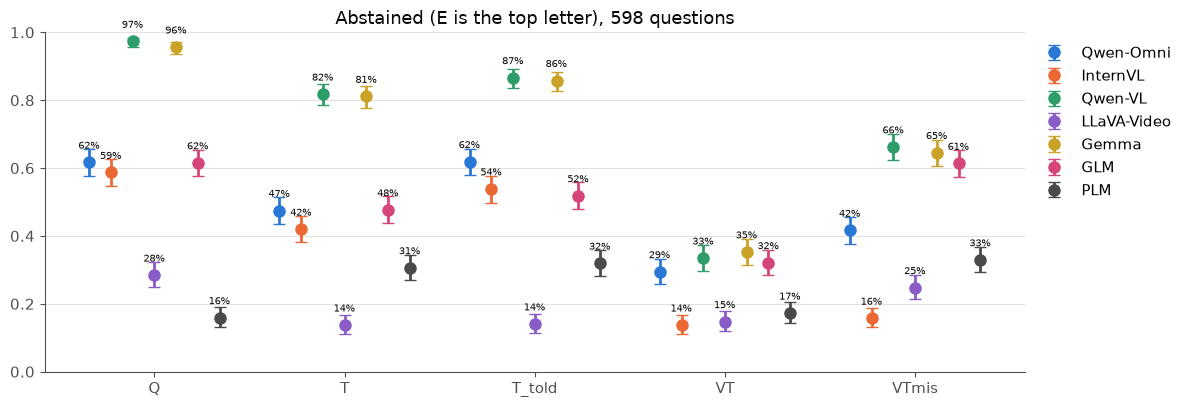

In [11]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e2dc"
COLORS = dict(zip(data, ["#2a78d6", "#eb6834", "#2e9d6a", "#8a5cc7", "#c9a227", "#d6457a", "#4a4a4a"]))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 11, "legend.frameon": False})


def dodge_plot(ax, column, conditions, title):
    for k, (name, df) in enumerate(data.items()):
        x = np.arange(len(conditions)) + (k - (len(data) - 1) / 2) * 0.8 / len(data)
        g = df.groupby("condition")[column]
        value = g.mean().reindex(conditions)
        lo, hi = zip(*[wilson(g.sum()[c], g.size()[c]) for c in conditions])
        ax.errorbar(x, value, yerr=[value - lo, np.array(hi) - value], fmt="o", ms=8, color=COLORS[name], capsize=4,
                    lw=2, label=name)
        for xi, v in zip(x, value):
            ax.text(xi, v + 0.04, f"{v:.0%}", ha="center", color=INK, fontsize=7)
    ax.set(xticks=range(len(conditions)), xticklabels=conditions, ylim=(0, 1), title=title)


fig, ax = plt.subplots(figsize=(12, 4.2))
dodge_plot(ax, "abstain", WITH_E, "Abstained (E is the top letter), 598 questions")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(FIGURES / "abstention_by_model.png", dpi=200)
plt.show()

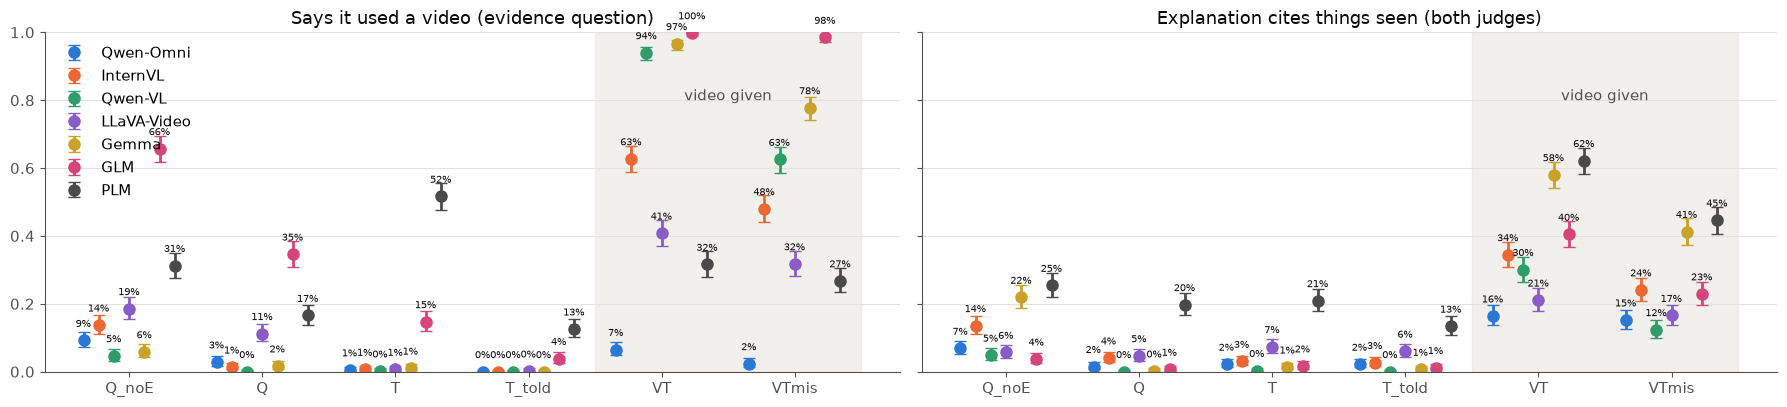

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4.2), sharey=True)
dodge_plot(axes[0], "claims_video", CONDITIONS, "Says it used a video (evidence question)")
dodge_plot(axes[1], "cites_visual", CONDITIONS, "Explanation cites things seen (both judges)")
for ax in axes:
    ax.axvspan(3.5, 5.5, color=GRID, alpha=0.5, zorder=0)
    ax.text(4.5, 0.8, "video given", ha="center", color=MUTED)
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "video_self_report_by_model.png", dpi=200)
plt.show()